# 00 · Exploración de PROFECO

**Pregunta del proyecto:** ¿en qué localidades una canasta comparable cuesta menos
y se percibe mayor seguridad?

Esta primera fase describe el archivo completo. No construye una canasta ni compara
el costo de vida. No incorpora ENSU todavía. Se conserva el CSV original.
La fuente fue declarada por el usuario; falta verificar su procedencia oficial.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/exploration.py").exists(), "Abrir desde la raíz del proyecto."
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.exploration import load_data, source_path, audit, export_results
pd.set_option("display.max_columns", 20)
path = source_path()
df = load_data(path)
print(f"Archivo: {path.name}; filas: {len(df):,}; columnas: {len(df.columns)}")
display(df.head(5))

Archivo: 08-2026_Q2.csv; filas: 657,602; columnas: 15


,producto,presentacion,marca,categoria,catalogo,precio,fecha_registro,cadena_comercial,giro,nombre_comercial,direccion,estado,municipio,latitud,longitud
0,Cebolla,1 Kg. Granel. Blanca. Primera,S/M,Hortalizas Frescas,Frutas y Legumbres,26,2026/08/17,Central de Abasto,Central de Abasto,Central de Abasto,Av. Mahatma Gandhi S/N. Salida a México. Col. ...,Aguascalientes,Aguascalientes,21.832072,-102.292976
1,Chile Fresco,1 Kg. Granel. Jalapeño. Primera,S/M,Hortalizas Frescas,Frutas y Legumbres,15,2026/08/17,Central de Abasto,Central de Abasto,Central de Abasto,Av. Mahatma Gandhi S/N. Salida a México. Col. ...,Aguascalientes,Aguascalientes,21.832072,-102.292976
2,Jitomate,1 Kg. Granel. Saladette/huaje o Tomate Saladet...,S/M,Hortalizas Frescas,Frutas y Legumbres,14,2026/08/17,Central de Abasto,Central de Abasto,Central de Abasto,Av. Mahatma Gandhi S/N. Salida a México. Col. ...,Aguascalientes,Aguascalientes,21.832072,-102.292976
3,Jitomate,1 Kg. Granel. Saladette/huaje o Tomate Saladet...,S/M,Hortalizas Frescas,Frutas y Legumbres,11,2026/08/17,Central de Abasto,Central de Abasto,Central de Abasto,Av. Mahatma Gandhi S/N. Salida a México. Col. ...,Aguascalientes,Aguascalientes,21.832072,-102.292976
4,Limón,1 Kg. Granel. Persa. Primera,S/M,Frutas Frescas,Frutas y Legumbres,10,2026/08/17,Central de Abasto,Central de Abasto,Central de Abasto,Av. Mahatma Gandhi S/N. Salida a México. Col. ...,Aguascalientes,Aguascalientes,21.832072,-102.292976


## 1. Definiciones y estructura

- Municipio: pareja exacta `estado` + `municipio`; todavía sin claves INEGI.
- Establecimiento: estado + municipio + cadena + nombre comercial + dirección.
  Es una aproximación operativa, no un identificador oficial.
- Producto: nombre distinto. Variante: producto + presentación + marca.
- Los campos se leen como texto para conservar el original, incluido `S/M`.
  Las conversiones numéricas y de fechas se realizan en variables auxiliares.
- No se eliminan duplicados ni anomalías. Los conteos incluyen registros originales.


In [2]:
display(pd.DataFrame({
    "tipo_lectura": df.dtypes.astype(str),
    "valores_distintos": df.nunique(),
}))
summary, tables = audit(df)
display(pd.Series(summary, name="valor").to_frame())

,tipo_lectura,valores_distintos
producto,string,756
presentacion,string,3011
marca,string,1003
categoria,string,42
catalogo,string,10
precio,string,16103
fecha_registro,string,12
cadena_comercial,string,197
giro,string,14
nombre_comercial,string,1735


,valor
registros,657602
columnas,15
estados,30
municipios_estado_municipio,72
nombres_municipio_distintos,70
establecimientos_clave_observada,1857
establecimientos_identidad_completa,1857
cadenas,197
productos_nombre,756
producto_presentaciones,3222


## 2. Cobertura geográfica y temporal

La tabla completa de municipios se exporta a CSV. El porcentaje de días compara
días observados con días calendario entre el mínimo y el máximo globales:
**no mide incumplimiento de un calendario de levantamiento**. Un municipio
presente en PROFECO todavía no es un área urbana comparable con ENSU.


In [3]:
municipios = tables["cobertura_municipios_profeco"]
display(tables["estados_profeco"])
with pd.option_context("display.max_rows", None):
    display(municipios[["estado", "municipio", "registros", "establecimientos",
                        "productos", "fecha_inicio", "fecha_fin", "dias_observados"]])
display(municipios[["registros", "establecimientos", "productos",
                   "variantes_producto_presentacion_marca", "dias_observados"]].describe())
display(tables["cobertura_diaria_profeco"])

,estado,registros
0,Aguascalientes,15867
1,Baja California,15254
2,Baja California Sur,15978
3,Campeche,16837
4,Chiapas,16408
5,Chihuahua,16295
6,Ciudad de México,125833
7,Coahuila,13991
8,Durango,12990
9,Estado de México,84295


,estado,municipio,registros,establecimientos,productos,fecha_inicio,fecha_fin,dias_observados
38,Guanajuato,León,31512,82,730,2026-08-17,2026-08-31,11
61,Tabasco,Centro,28863,66,721,2026-08-17,2026-08-31,11
8,Ciudad de México,Benito Juárez,28804,25,719,2026-08-17,2026-08-31,8
41,Jalisco,Guadalajara,17602,70,689,2026-08-16,2026-08-31,12
3,Campeche,Campeche,16837,50,697,2026-08-17,2026-08-31,11
4,Chiapas,Tuxtla Gutiérrez,16408,49,692,2026-08-17,2026-08-31,11
2,Baja California Sur,La Paz,15978,53,673,2026-08-17,2026-08-31,11
60,Sonora,Hermosillo,15935,42,698,2026-08-17,2026-08-31,11
0,Aguascalientes,Aguascalientes,15867,48,705,2026-08-17,2026-08-31,11
54,Puebla,Puebla,15437,44,726,2026-08-17,2026-08-31,11


,registros,establecimientos,productos,variantes_producto_presentacion_marca,dias_observados
count,72.000000,72.000000,72.000000,72.000000,72.000000
mean,9133.361111,25.791667,557.305556,1837.097222,6.736111
std,7020.773743,19.609524,221.035377,824.012703,3.936085
min,2.000000,1.000000,1.000000,1.000000,1.000000
25%,3391.000000,6.750000,523.250000,1553.750000,3.000000
50%,8988.500000,25.000000,661.000000,2166.000000,6.000000
75%,13742.000000,41.250000,699.250000,2432.500000,11.000000
max,31512.000000,82.000000,730.000000,2994.000000,12.000000


,fecha,registros,establecimientos
0,2026-08-16,2,1
1,2026-08-17,57260,331
2,2026-08-18,63086,331
3,2026-08-19,59366,324
4,2026-08-20,62160,337
5,2026-08-21,60490,332
6,2026-08-22,0,0
7,2026-08-23,0,0
8,2026-08-24,58728,325
9,2026-08-25,60148,335


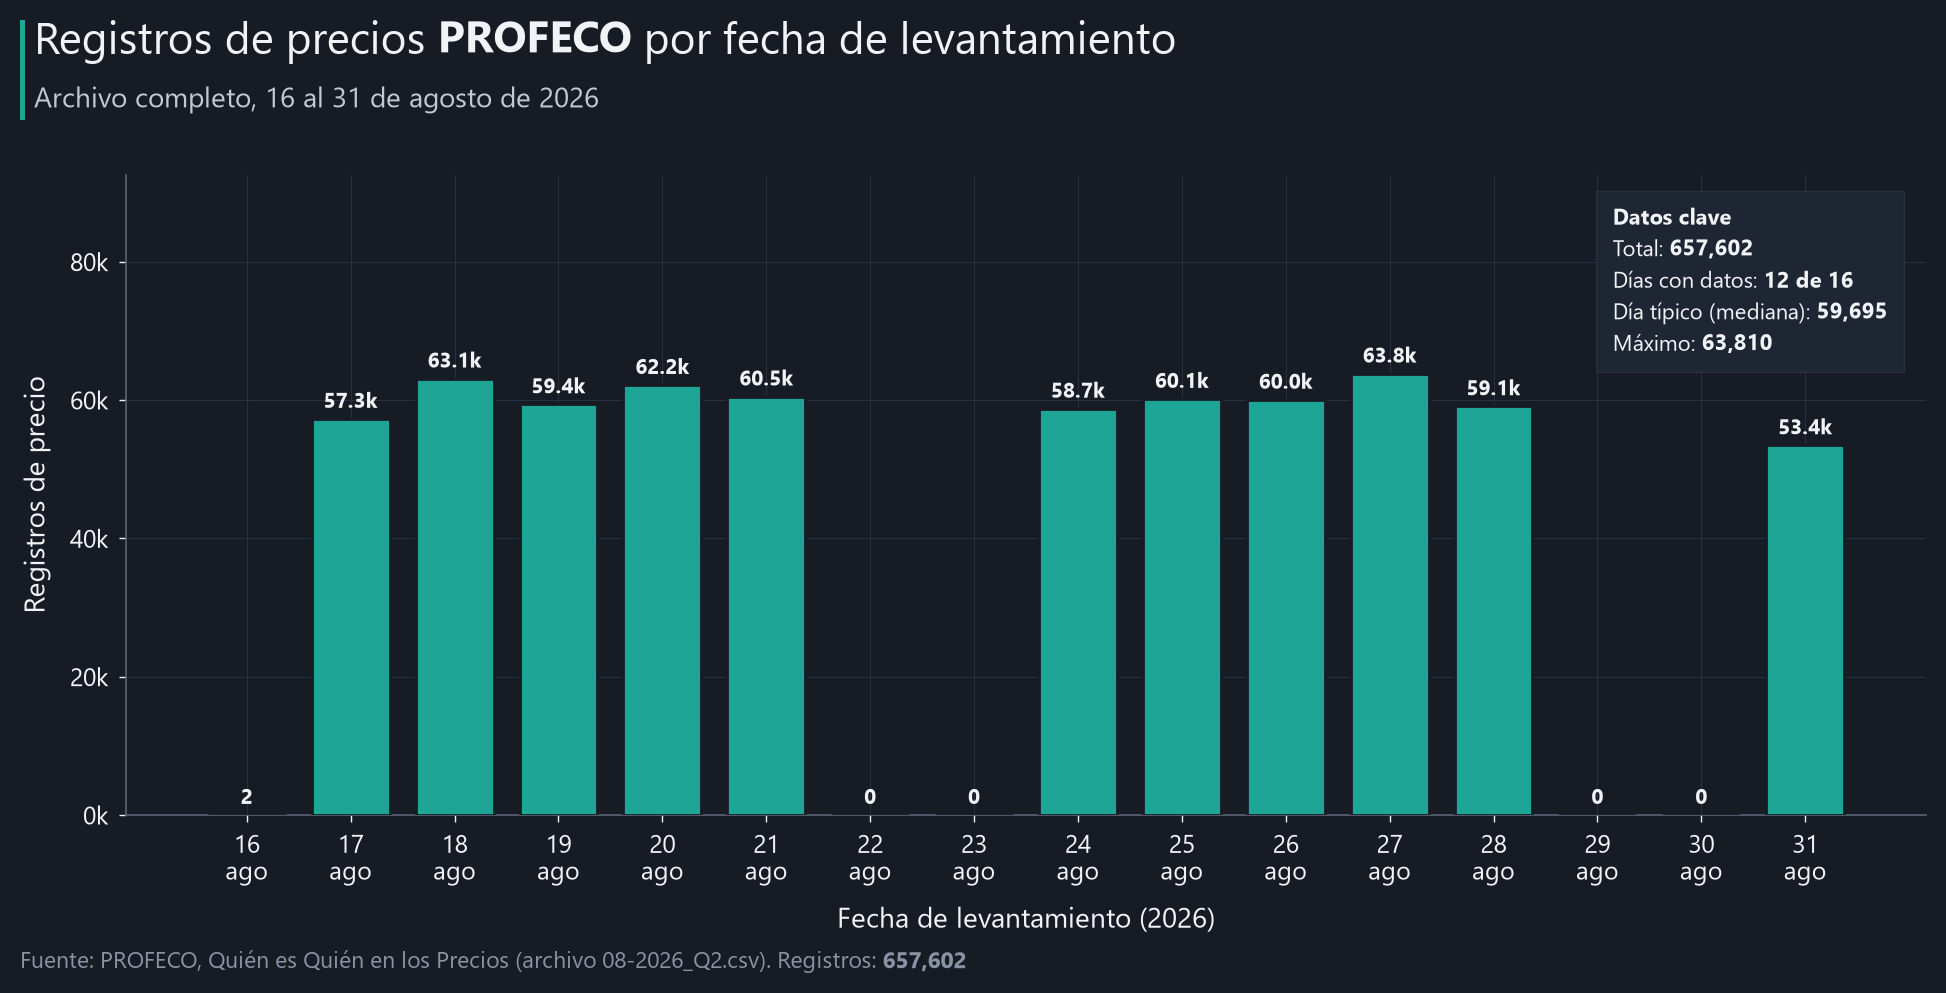

In [4]:
from src import charts
daily = tables["cobertura_diaria_profeco"]
(ROOT / "outputs/charts").mkdir(parents=True, exist_ok=True)
charts.daily_bars(daily, ROOT / "outputs/charts/01_cobertura_temporal.png")
plt.show()

## 3. Cobertura de productos

El denominador es el número de parejas estado–municipio con geografía completa.
Se exige producto, presentación y marca no vacíos para esta tabla.
La coincidencia literal de presentación no demuestra equivalencia de unidades.
Esta cobertura es descriptiva: no se han seleccionado alimentos ni una canasta.


In [5]:
display(tables["catalogos_categorias_profeco"])
productos = tables["cobertura_productos_profeco"]
display(productos.head(25))
display(productos["cobertura_municipios_pct"].describe())
print("Variantes presentes en todos los municipios:",
      int(productos.municipios.eq(summary["municipios_estado_municipio"]).sum()))

,catalogo,categoria,registros
46,Medicamentos,Medicamentos,137791
96,Útiles Escolares,Material Escolar,59835
5,Básicos,Arts. para el Cuidado Personal,45994
16,Básicos,Derivados de Leche,28037
37,Electrodomésticos,Aparatos Eléctricos,26352
...,...,...,...
65,Mercados,Huevo,85
50,Mercados,Arts. para el Cuidado Personal,71
86,PACIC,Leche Fresca,21
66,Mercados,Leche Fresca,11


,producto,presentacion,marca,registros,establecimientos,municipios,cobertura_municipios_pct
3571,Tortilla de Maíz,1 Kg. Granel,S/M,2257,929,70,97.222222
2169,Limón,1 Kg. Granel. Agrio Sin Semilla o Persa,S/M,963,327,65,90.277778
2813,Plátano,1 Kg. Granel. Tabasco/chiapas/roatán/portalimón,S/M,1172,375,65,90.277778
2273,Manzana,1 Kg. Granel. Red Delicious/roja/roja Mediana/...,S/M,1140,368,65,90.277778
1953,Jitomate,1 Kg. Granel. Saladette/huaje o Tomate Saladet...,S/M,1165,382,65,90.277778
3718,Zanahoria,1 Kg. Granel. Mediana,S/M,1064,353,65,90.277778
59,Agrifen,Caja con 10 Tabletas,S/M,755,413,64,88.888889
1357,Elote,Lata 220 Gr. en Grano,Herdez,642,349,64,88.888889
3191,Salsa Picante y Similares,Botella 150 Gr. Clásica,Búfalo,547,303,64,88.888889
628,Carne Cerdo,1 Kg. Granel. Manitas,S/M,537,307,64,88.888889


count    3724.000000
mean       49.331290
std        29.218180
min         1.388889
25%        20.833333
50%        55.555556
75%        76.388889
max        97.222222
Name: cobertura_municipios_pct, dtype: float64

Variantes presentes en todos los municipios: 0


## 4. Controles de calidad

Duplicados excedentes: repeticiones después de la primera fila idéntica en las
15 columnas. La comparación de precios extremos se pospone hasta definir
productos homogéneos; un IQR global mezclaría bienes diferentes.

La revisión textual de geografía elimina acentos, espacios redundantes y
diferencias de mayúsculas **solo para detectar posibles variantes**.
No fusiona municipios. Las coordenadas se revisan por rango mundial, sin
certificar que correspondan al municipio declarado.


In [6]:
display(tables["controles_calidad_profeco"])
display(tables["nulos_profeco"])
display(tables["variantes_geograficas_revision"])
display(tables["muestra_anomalias_profeco"].head(10))
assert municipios.registros.sum() + int(
    tables["controles_calidad_profeco"].set_index("control").loc[
        "geografia_incompleta", "registros"]) == len(df)
assert municipios[["estado", "municipio"]].duplicated().sum() == 0
assert productos.cobertura_municipios_pct.between(0, 100).all()
print("Reconciliaciones y controles estructurales: correctos.")

,control,registros
0,duplicados_excedentes_exactos,0
1,filas_en_grupos_duplicados,0
2,precio_vacio,0
3,precio_no_numerico_no_vacio,0
4,precio_no_finito_no_nulo,0
5,precio_cero_o_negativo,0
6,fecha_vacia,0
7,fecha_invalida_no_vacia,0
8,geografia_incompleta,0
9,identidad_establecimiento_incompleta,0


,columna,vacios,vacios_pct
0,producto,0,0.0
1,presentacion,0,0.0
2,marca,0,0.0
3,categoria,0,0.0
4,catalogo,0,0.0
5,precio,0,0.0
6,fecha_registro,0,0.0
7,cadena_comercial,0,0.0
8,giro,0,0.0
9,nombre_comercial,0,0.0


,estado,municipio,estado_revision,municipio_revision


,fila_datos_1_based,producto,presentacion,marca,categoria,catalogo,precio,fecha_registro,cadena_comercial,giro,nombre_comercial,direccion,estado,municipio,latitud,longitud
96639,96640,Aceite,Botella 850 Ml. Vegetal,Gran Tradición,Aceites y Grasas Veg. Comestibles,PACIC,30,2026/08/19,Bodega Aurrera,Supermercado / Tienda de Autoservicio,Bodega Aurrera Sucursal Observatorio,Observatorio 457. Col. las Americas. Cp. 01120,Ciudad de México,Álvaro Obregón,,
96640,96641,Aceite,Botella 946 Ml. Soya,Great Value,Aceites y Grasas Veg. Comestibles,PACIC,42,2026/08/19,Bodega Aurrera,Supermercado / Tienda de Autoservicio,Bodega Aurrera Sucursal Observatorio,Observatorio 457. Col. las Americas. Cp. 01120,Ciudad de México,Álvaro Obregón,,
96641,96642,Arroz,Bolsa 900 Gr. Extra,Aurrera,Arroz y Cereales Preparados,PACIC,14,2026/08/19,Bodega Aurrera,Supermercado / Tienda de Autoservicio,Bodega Aurrera Sucursal Observatorio,Observatorio 457. Col. las Americas. Cp. 01120,Ciudad de México,Álvaro Obregón,,
96642,96643,Arroz,Bolsa 900 Gr. Super Extra,Aurrera,Arroz y Cereales Preparados,PACIC,14,2026/08/19,Bodega Aurrera,Supermercado / Tienda de Autoservicio,Bodega Aurrera Sucursal Observatorio,Observatorio 457. Col. las Americas. Cp. 01120,Ciudad de México,Álvaro Obregón,,
96643,96644,Arroz,Bolsa 907 Gr. Super Extra,Schettino,Arroz y Cereales Preparados,PACIC,18,2026/08/19,Bodega Aurrera,Supermercado / Tienda de Autoservicio,Bodega Aurrera Sucursal Observatorio,Observatorio 457. Col. las Americas. Cp. 01120,Ciudad de México,Álvaro Obregón,,
96644,96645,Atún,Lata 140 Gr. en Hojuelas en Agua,Great Value,Pescados y Mariscos en Conserva,PACIC,15,2026/08/19,Bodega Aurrera,Supermercado / Tienda de Autoservicio,Bodega Aurrera Sucursal Observatorio,Observatorio 457. Col. las Americas. Cp. 01120,Ciudad de México,Álvaro Obregón,,
96645,96646,Azúcar,Bolsa Plástico 900 Gr. Estándar,Aurrera,Azúcar,PACIC,22,2026/08/19,Bodega Aurrera,Supermercado / Tienda de Autoservicio,Bodega Aurrera Sucursal Observatorio,Observatorio 457. Col. las Americas. Cp. 01120,Ciudad de México,Álvaro Obregón,,
96646,96647,Azúcar,Bolsa Plástico 900 Gr. Estándar,Zulka,Azúcar,PACIC,27,2026/08/19,Bodega Aurrera,Supermercado / Tienda de Autoservicio,Bodega Aurrera Sucursal Observatorio,Observatorio 457. Col. las Americas. Cp. 01120,Ciudad de México,Álvaro Obregón,,
96647,96648,Carne Cerdo,1 Kg. Granel. Chuleta Arriera o Chuleta Mixta,S/M,Carne y Vísceras de Cerdo,PACIC,76,2026/08/19,Bodega Aurrera,Supermercado / Tienda de Autoservicio,Bodega Aurrera Sucursal Observatorio,Observatorio 457. Col. las Americas. Cp. 01120,Ciudad de México,Álvaro Obregón,,
96648,96649,Carne Cerdo,1 Kg. Granel. Costilla,S/M,Carne y Vísceras de Cerdo,PACIC,148,2026/08/19,Bodega Aurrera,Supermercado / Tienda de Autoservicio,Bodega Aurrera Sucursal Observatorio,Observatorio 457. Col. las Americas. Cp. 01120,Ciudad de México,Álvaro Obregón,,


Reconciliaciones y controles estructurales: correctos.


## 5. Exportación y conclusiones

Se guardan tablas de cobertura, controles y metadatos con SHA-256.
La ruta local se registra por separado (`data/metadata/ruta_local.txt`).
No se crea todavía `auditoria_cobertura.csv`: esa validación requiere ENSU
y la cobertura de la canasta.


In [7]:
export_results(summary, tables, path)
controls = tables["controles_calidad_profeco"].set_index("control").registros
display(Markdown(
    f"Se observaron **{summary['registros']:,} registros**, "
    f"**{summary['municipios_estado_municipio']} municipios** en "
    f"**{summary['estados']} entidades**, entre "
    f"**{summary['fecha_inicio']}** y **{summary['fecha_fin']}**.\n\n"
    f"Hay **{summary['establecimientos_clave_observada']:,} claves de establecimiento** "
    f"y **{summary['productos_nombre']:,} nombres de producto**. "
    f"Los duplicados excedentes exactos son **{controls['duplicados_excedentes_exactos']:,}**.\n\n"
    "Estos resultados describen la muestra del archivo, no la oferta total de cada ciudad. "
    "La siguiente fase debe verificar el periodo y la geografía ENSU antes de unir fuentes."
))

Se observaron **657,602 registros**, **72 municipios** en **30 entidades**, entre **2026-08-16** y **2026-08-31**.

Hay **1,857 claves de establecimiento** y **756 nombres de producto**. Los duplicados excedentes exactos son **0**.

Estos resultados describen la muestra del archivo, no la oferta total de cada ciudad. La siguiente fase debe verificar el periodo y la geografía ENSU antes de unir fuentes.